In [ ]:
pip install ipympl ipywidgets pandas

### Get trajectory

In [1]:
# file_path = '/data/horse/ws/miha493e-research_project/activediffusion/data/molecules-fps-40000.hdf5'
# file_path = '/data/horse/ws/miha493e-research_project/activediffusion/experiments/exp8/results/descriptors_fps_5000/molecules-fps-5000.hdf5'
file_path = '/data/horse/ws/miha493e-research_project/activediffusion/data/data_embd_jmp/hdf5/molecules-fps-40000-output.hdf5'

In [2]:
%matplotlib widget

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import h5py
import pandas as pd
import ipywidgets as widgets
from ipywidgets import VBox, HBox, Button, Output, Dropdown
from IPython.display import display, clear_output



### 2D trajectory

In [7]:
def extract_properties2(file_path, property1, property2):
    property1_values, property2_values = [], []
    with h5py.File(file_path, "r") as f:
        for subset in f.keys():
            if isinstance(f[subset], h5py.Group):
                for geom in f[subset].keys():
                    if property1 in f[subset][geom].keys() and property2 in f[subset][geom].keys():
                        prop1 = f[subset][geom][property1][()]
                        prop2 = f[subset][geom][property2][()]
                        if hasattr(prop1, 'shape') and prop1.shape == (): prop1 = float(prop1)
                        if hasattr(prop2, 'shape') and prop2.shape == (): prop2 = float(prop2)
                        property1_values.append(prop1)
                        property2_values.append(prop2)
    return property1_values, property2_values

In [ ]:
def show_properties2(prop1_name, prop1_values, prop2_name, prop2_values):
    global fig, ax, scatter, cid, line, clicked_points
    clicked_points = []  # reset each time

    if prop1_name == 'atNUM':
        prop1_values = [len(v) for v in prop1_values]
    if prop2_name == 'atNUM':
        prop2_values = [len(v) for v in prop2_values]

    prop1_values = np.array(prop1_values).flatten()
    prop2_values = np.array(prop2_values).flatten()

    fig, ax = plt.subplots(figsize=(8,6))
    scatter = ax.scatter(prop1_values, prop2_values, s=5, alpha=0.5)
    ax.set_xlabel(prop1_name)
    ax.set_ylabel(prop2_name)
    ax.set_title(f"Click points on {prop1_name} vs {prop2_name}")
    ax.grid(True, linestyle='--', alpha=0.3)

    # line for picked points
    (line,) = ax.plot([], [], marker='o', color='red')

    # click handler
    def on_click(event):
        if event.inaxes != ax or event.button != 1:  # left clicks only
            return
        x, y = round(event.xdata, 1), round(event.ydata, 1)
        clicked_points.append((x, y))
        xs = [p[0] for p in clicked_points]
        ys = [p[1] for p in clicked_points]
        line.set_data(xs, ys)
        fig.canvas.draw_idle()

    cid = fig.canvas.mpl_connect("button_press_event", on_click)

In [ ]:

# --- Global state ---
clicked_points = []
fig = None
ax = None
scatter = None
cid = None
line = None
out = Output()

# --- Molecule properties list ---
molecule_prop = [
    'DIP','HLgap','atNUM','eAT','eC','eEE','eH','eKIN','eL','eMBD',
    'eNE','eNN','ePBE0','ePBE0+MBD','eTS','eX','eXC','eXX','mC6','mPOL'
]

# --- Dropdowns & button ---
prop1_dropdown = Dropdown(options=molecule_prop, description='Molecule Property 1:', style={'description_width': 'initial'})
prop2_dropdown = Dropdown(options=molecule_prop, description='Molecule Property 2:', style={'description_width': 'initial'})
show_button = Button(description="Show Plot")

output2 = Output()

def on_show_plot(b):
    with output2:
        clear_output()
        x_values, y_values = extract_properties2(file_path, prop1_dropdown.value, prop2_dropdown.value)
        print(f"Extracted {len(x_values)} points for {prop1_dropdown.value} and {prop2_dropdown.value}.")
        show_properties2(prop1_dropdown.value, x_values, prop2_dropdown.value, y_values)

# --- Buttons for point picking ---
save_btn = Button(description="Save CSV")
undo_btn = Button(description="Undo")
clear_btn = Button(description="Clear")
stop_btn = Button(description="Stop Picking")

def on_save(_):
    if not clicked_points:
        with out:
            print("No points to save.")
        return
    
    # Save clicked points as CSV
    df = pd.DataFrame(clicked_points, columns=["x", "y"])
    df.to_csv(f"trajectory_{prop1_dropdown.value}_{prop2_dropdown.value}.csv", index=False)
    
    # Save current figure with highlighted points
    if 'fig' in globals() and 'ax' in globals():
        if clicked_points:
            xs, ys = zip(*clicked_points)
            ax.scatter(xs, ys, c='red', s=20, label="Picked Points")
            ax.legend()
        fig.savefig(f"trajectory_{prop1_dropdown.value}_{prop2_dropdown.value}.png", dpi=300)
    
    with out:
        print(f"Saved picked_points.csv with {len(clicked_points)} points.")
        print("Saved picked_points_plot.png with clicked points highlighted.")


def on_undo(_):
    if clicked_points:
        clicked_points.pop()
        xs = [p[0] for p in clicked_points]
        ys = [p[1] for p in clicked_points]
        line.set_data(xs, ys)
        fig.canvas.draw_idle()

def on_clear(_):
    clicked_points.clear()
    line.set_data([], [])
    fig.canvas.draw_idle()

def on_stop(_):
    global cid
    if fig and cid:
        fig.canvas.mpl_disconnect(cid)
        with out: print("Click picking disabled.")


save_btn.on_click(on_save)
undo_btn.on_click(on_undo)
clear_btn.on_click(on_clear)
stop_btn.on_click(on_stop)

# --- Connect dropdown logic ---
show_button.on_click(on_show_plot)

# --- Display ---
display(VBox([
    prop1_dropdown,
    HBox([prop2_dropdown, show_button]),
    output2,
    HBox([save_btn, undo_btn, clear_btn, stop_btn]),
    out
]))

### 3D trajectory

In [4]:
def extract_properties3(file_path, property1, property2, property3):
    """
    Extract arrays for 'HLgap' and 'eMBD' from the specified HDF5 file and dataset.

    Parameters:
    -----------
    file_path : str
        Path to the HDF5 file.
    property1 : str
        The first property to extract (e.g., 'HLgap').
    property2 : str
        The second property to extract (e.g., 'eMBD').
    property3 : str
        The third property to extract (e.g., 'atNUM').

    Returns:
    --------
    tuple
        Two lists containing the extracted values for the specified properties.
    """

    property1_values = []
    property2_values = []
    property3_values = []

    with h5py.File(file_path, "r") as f:
        for subset in f.keys():
            if isinstance(f[subset], h5py.Group):
                for geom in f[subset].keys():
                    if property1 in f[subset][geom].keys() and property2 in f[subset][geom].keys() and property3 in f[subset][geom].keys():
                        prop1 = f[subset][geom][property1][()]
                        prop2 = f[subset][geom][property2][()]
                        prop3 = f[subset][geom][property3][()]

                        # Convert to scalar if numpy array with zero dims
                        if hasattr(prop1, 'shape') and prop1.shape == ():
                            prop1 = float(prop1)
                        if hasattr(prop2, 'shape') and prop2.shape == ():
                            prop2 = float(prop2)
                        if hasattr(prop3, 'shape') and prop3.shape == ():
                            prop3 = float(prop3)

                        property1_values.append(prop1)
                        property2_values.append(prop2)
                        property3_values.append(prop3)

    return property1_values, property2_values, property3_values

In [5]:
def _clean_property_values(name, values):
    """Convert 'atNUM' arrays to counts and flatten all values."""
    if name == 'atNUM':
        values = [len(v) for v in values]
    return np.array(values).flatten()

def show_properties3(
    x_name, x_values,
    y_name, y_values,
    c_name, c_values,
    gridsize=50,
    cmap='viridis',
    vmin=None,
    vmax=None
):
    """
    Interactive hexbin plot where clicking a hexagon prints the data points inside.

    Parameters
    ----------
    x_name, y_name, c_name : str
        Property names for x, y, and color axis.
    x_values, y_values, c_values : list or array
        Property values for x, y, and color axis.
    gridsize : int
        Resolution of hexagonal bins.
    cmap : str
        Colormap for the hexbin.
    vmin, vmax : float, optional
        Value limits for color scaling.
    """
    global fig, ax, scatter, cid, line, clicked_points
    clicked_points = []  # reset each time
    # Clean & flatten
    x_values = _clean_property_values(x_name, x_values)
    y_values = _clean_property_values(y_name, y_values)
    c_values = _clean_property_values(c_name, c_values)

    fig, ax = plt.subplots(figsize=(8,6))
    hb = ax.hexbin(
        x_values, y_values, C=c_values,
        gridsize=gridsize,
        mincnt=1,
        reduce_C_function=np.mean,
        cmap=cmap,
        vmin=vmin, vmax=vmax
    )
    cb = plt.colorbar(hb, ax=ax, label=f"mean {c_name}")
    ax.set_xlabel(x_name)
    ax.set_ylabel(y_name)
    ax.set_title(f"{x_name} vs {y_name} colored by {c_name}")
    ax.grid(True, linestyle="--", alpha=0.3)

    # line for picked points
    (line,) = ax.plot([], [], marker='o', color='red')

    # click handler
    def on_click(event):
        if event.inaxes != ax or event.button != 1:  # left clicks only
            return
        x, y = round(event.xdata, 1), round(event.ydata, 1)
        # Get hexbin centers and corresponding C values
        offsets = hb.get_offsets()  # shape (n_hex, 2)
        cvals = hb.get_array()      # reduced C values
        
        # Find nearest hexagon center
        distances = np.hypot(offsets[:,0] - x, offsets[:,1] - y)
        idx = np.argmin(distances)
        
        # Get the reduced C value at this hex
        c = cvals[idx]
        
        clicked_points.append((x, y, c))
        xs = [p[0] for p in clicked_points]
        ys = [p[1] for p in clicked_points]
        line.set_data(xs, ys)
        fig.canvas.draw_idle()

    cid = fig.canvas.mpl_connect("button_press_event", on_click)


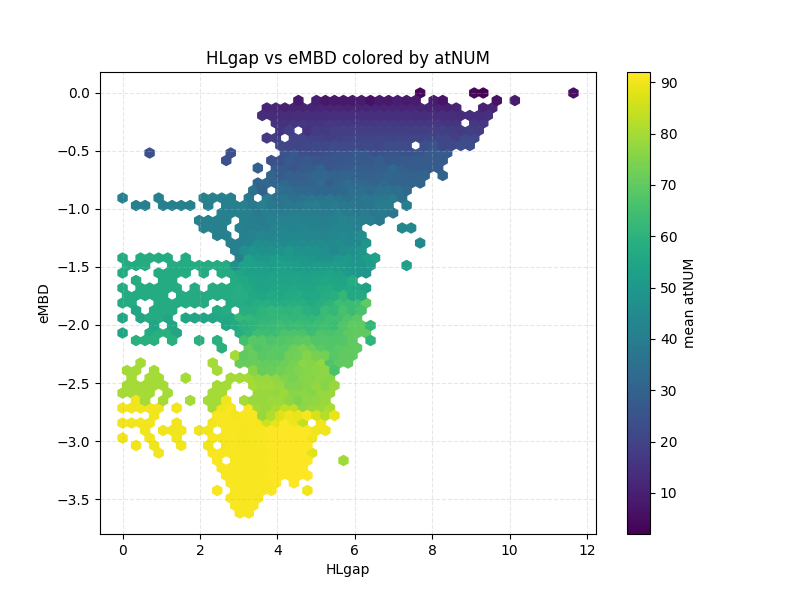

In [6]:
# --- Global state ---
clicked_points = []
fig = None
ax = None
scatter = None
cid = None
line = None
# output3 = Output()


# Your property list
molecule_prop = [
    'DIP', 'HLgap', 'atNUM', 'eAT', 'eC', 'eEE', 'eH',
    'eKIN', 'eL', 'eMBD', 'eNE', 'eNN', 'ePBE0', 'ePBE0+MBD',
    'eTS', 'eX', 'eXC', 'eXX', 'mC6', 'mPOL'
]

# Widgets
prop1_dropdown = widgets.Dropdown(options=molecule_prop, description='X-axis Property:', style={'description_width': 'initial'})
prop2_dropdown = widgets.Dropdown(options=molecule_prop, description='Y-axis Property:', style={'description_width': 'initial'})
prop3_dropdown = widgets.Dropdown(options=molecule_prop, description='Z-axis Property:', style={'description_width': 'initial'})
show_button = widgets.Button(description="Show 3D Plot")
save_button = widgets.Button(description="Save Plot + CSV")
undo_btn = Button(description="Undo")
clear_btn = Button(description="Clear")
stop_btn = Button(description="Stop Picking")
output3 = widgets.Output()

# --- Extra property widgets ---
sascore_btn = widgets.ToggleButton(value=False, description="Add SAScore")
qed_btn = widgets.ToggleButton(value=False, description="Add QED")

sascore_box = widgets.VBox([])  # will hold editable fields
qed_box = widgets.VBox([])

# --- Function to save the trajectory ---
def save_trajectory():
    if not clicked_points:
        with output3:
            print("No points to save.")
        return

    if 'fig' in globals() and 'ax' in globals():
        if clicked_points:
            xs, ys, cs = zip(*clicked_points)
            ax.scatter(xs, ys, c='red', s=20, label="Picked Points")
            ax.legend()
        fig.savefig(f"trajectory_{prop1_dropdown.value}_{prop2_dropdown.value}_{prop3_dropdown.value}.png", dpi=300)

        # base dataframe
        df = pd.DataFrame(clicked_points, columns=[prop1_dropdown.value, prop2_dropdown.value, prop3_dropdown.value])

        # if SAScore active
        if sascore_btn.value and sascore_box.children:
            values = [w.value for w in sascore_box.children if isinstance(w, widgets.FloatText)]
            df["SAScore"] = values

        # if QED active
        if qed_btn.value and qed_box.children:
            values = [w.value for w in qed_box.children if isinstance(w, widgets.FloatText)]
            df["QEDScore"] = values

        csvpath = f"trajectory_{prop1_dropdown.value}_{prop2_dropdown.value}_{prop3_dropdown.value}.csv"
        df.to_csv(csvpath, index=False)
        with output3:
            print(f"Clicked points saved to {csvpath}")

# --- Function to add SAScore and QED widgets ---
def refresh_property_tables():
    """Regenerate editable tables for SAScore and QED according to clicked_points length."""
    n = len(clicked_points)
    if sascore_btn.value:
        sascore_box.children = [widgets.Label("SAScore values:")] + \
            [widgets.FloatText(value=0.0) for _ in range(n)]
    else:
        sascore_box.children = []

    if qed_btn.value:
        qed_box.children = [widgets.Label("QED values:")] + \
            [widgets.FloatText(value=0.0) for _ in range(n)]
    else:
        qed_box.children = []



def on_show_plot(b):
    """Show the 3D scatter plot."""
    global fig, ax3d, current_data, clicked_points, xs, ys, zs
    with output3:
        clear_output(wait=True)
        x_axis, y_axis, z_axis = prop1_dropdown.value, prop2_dropdown.value, prop3_dropdown.value
        x_values, y_values, z_values = extract_properties3(file_path, x_axis, y_axis, z_axis)
        show_properties3(x_axis, x_values, y_axis, y_values, z_axis, z_values)

def on_undo(_):
    if clicked_points:
        clicked_points.pop()
        xs = [p[0] for p in clicked_points]
        ys = [p[1] for p in clicked_points]
        line.set_data(xs, ys)
        fig.canvas.draw_idle()

def on_clear(_):
    clicked_points.clear()
    line.set_data([], [])
    fig.canvas.draw_idle()

def on_stop(_):
    global cid
    if fig and cid:
        fig.canvas.mpl_disconnect(cid)
        with output3: print("Click picking disabled.")

def on_toggle_change(change):
    refresh_property_tables()

def on_save_plot(b):
    save_trajectory()
    
# Bind callbacks
show_button.on_click(on_show_plot)
save_button.on_click(on_save_plot)
undo_btn.on_click(on_undo)
clear_btn.on_click(on_clear)
stop_btn.on_click(on_stop)
sascore_btn.observe(on_toggle_change, 'value')
qed_btn.observe(on_toggle_change, 'value')

# --- Display UI including new buttons ---
display(widgets.VBox([
    prop1_dropdown,
    prop2_dropdown,
    prop3_dropdown,
    widgets.HBox([show_button, save_button]),
    widgets.HBox([undo_btn, clear_btn]),
    widgets.HBox([sascore_btn, qed_btn]),   # <-- toggle buttons
    sascore_box, qed_box,                   # <-- editable tables appear here
    output3
]))

